*Previous notebook: the perceptron (village-fair example) and the AND function built from scratch with a single neuron. — This notebook: from a single neuron to a network, and the main activation functions (sigmoid, tanh, ReLU, Leaky ReLU, ELU, GELU, Swish, Softmax).*

## From a Single Neuron to a Network

A single perceptron can only compute **linearly separable** functions. To solve more complex problems, we stack neurons into **layers**:



For a network with $L$ layers, the output of layer $l$ is computed via **forward propagation**:

$$\mathbf{a}^{(l)} = \sigma\!\left(W^{(l)}\, \mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}\right)$$

where:
- $W^{(l)}$ — **weight matrix** for layer $l$
- $\mathbf{b}^{(l)}$ — **bias vector** for layer $l$
- $\mathbf{a}^{(l-1)}$ — activations from the previous layer, with $\mathbf{a}^{(0)} = \mathbf{x}$
- $\sigma(\cdot)$ — a non-linear **activation function** applied element-wise

The network **learns** by adjusting $W^{(l)}$ and $\mathbf{b}^{(l)}$ to minimise a **loss function** $\mathcal{L}(\hat{y}, y)$ via **gradient descent**:

$$W^{(l)} \leftarrow W^{(l)} - \eta \frac{\partial \mathcal{L}}{\partial W^{(l)}}$$

where $\eta > 0$ is the **learning rate**. Gradients are propagated backwards using the chain rule (**backpropagation**). Through many iterations over training data, the network learns a mapping from inputs to outputs without explicit rules.

Disadvantage of single perceptron is that it only output binary values and if we try to give small change in weight and bias then perceptron can flip the output. We need some system which can modify the output slightly according to small change in weight and bias. Here comes sigmoid function in picture.

If we change perceptron with a sigmoid/tanh function, then we can make slight change in output. But the number of activation functions are large. Nowadays, RELU is the most used activation function.

## Exploring activation functions


An activation function, also known as a transfer function, plays a vital role in neural
networks. It is used to introduce non-linearity in neural networks. As we learned before, we
apply the activation function to the input, which is multiplied by weights and added to the
bias, that is, $f(z)$ , where z = (input * weights) + bias and $f(\cdot)$ is the activation function. If we do
not apply the activation function, then a neuron simply resembles the linear regression. Also with more neurons, remains linear (not sufficient for complex problems). The
aim of the activation function is to introduce a non-linear transformation to learn the
complex underlying patterns in the data.


### Overview

Activation functions introduce **non-linearity** into neural networks — without them, stacking layers would collapse into a single linear transformation and the network could not learn complex patterns.

Below we explore the most important activation functions. A few notable ones beyond the list above:
- **Softplus** $\log(1+e^z)$: smooth ReLU approximation
- **SELU** (Scaled ELU): self-normalizing, preserves mean/variance through layers
- **Mish** $z\cdot\tanh(\text{softplus}(z))$: smooth, non-monotonic, used in YOLOv4

| Function | Formula | Output range | Zero-centered | Vanishing gradient |
|:---------|:--------|:------------:|:-------------:|:------------------:|
| Sigmoid  | $\frac{1}{1+e^{-z}}$ | $(0,1)$ | No | Yes |
| Tanh     | $\frac{e^z-e^{-z}}{e^z+e^{-z}}$ | $(-1,1)$ | Yes | Yes |
| ReLU     | $\max(0,z)$ | $[0,+\infty)$ | No | No (for $z>0$) |
| Leaky ReLU | $\max(\alpha z,z)$, $\alpha{=}0.01$ | $(-\infty,+\infty)$ | No | No |
| ELU      | $z$ if $z{>}0$, else $\alpha(e^z{-}1)$ | $(-\alpha,+\infty)$ | ~Yes | No |
| GELU     | $z\,\Phi(z)$ | $(-\infty,+\infty)$ | ~Yes | No |
| Swish    | $z\cdot\sigma(z)$ | $(-\infty,+\infty)$ | ~Yes | No |
| Softmax  | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | $(0,1)$, sums to 1 | No | — |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Sigmoid  $\sigma(z) = \dfrac{1}{1+e^{-z}}$

**Pros:** smooth and differentiable everywhere; output interpretable as a probability $(0,1)$.  
**Cons:** vanishing gradients for large $|z|$ (saturates near 0 and 1); output not zero-centered (slows learning); slower than ReLU.

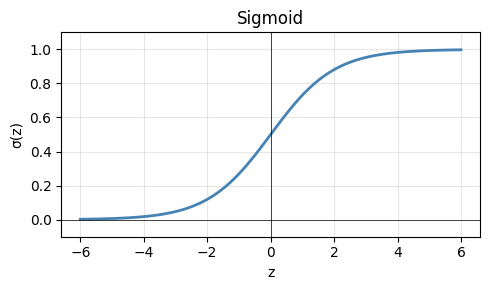

In [2]:
z = np.linspace(-6, 6, 400)

def sigmoid(z):
    return 1 / (1+np.exp(-z))

y = sigmoid(z)

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='steelblue', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.ylim(-0.1, 1.1); plt.title('Sigmoid'); plt.xlabel('z'); plt.ylabel('σ(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### $\tanh(z) = \dfrac{e^z - e^{-z}}{e^z + e^{-z}}$

**Pros:** zero-centered output $(-1,1)$, stronger gradients than sigmoid near 0.  
**Cons:** still saturates for large $|z|$ (vanishing gradient); more expensive than ReLU.

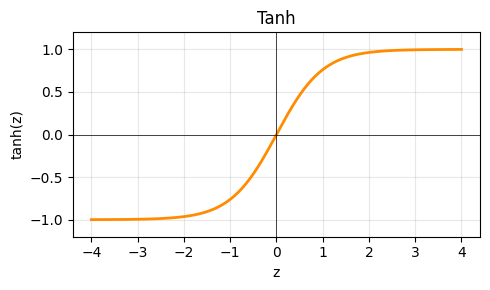

In [3]:
z = np.linspace(-4, 4, 400)
y = np.tanh(z)

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='darkorange', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.ylim(-1.2, 1.2); plt.title('Tanh'); plt.xlabel('z'); plt.ylabel('tanh(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### ReLU  $\text{ReLU}(z) = \max(0, z)$

**Pros:** no vanishing gradient for $z>0$; computationally cheap; promotes sparse activations.  
**Cons:** *dying ReLU* — neurons with $z<0$ always output 0 and stop learning; output not zero-centered.

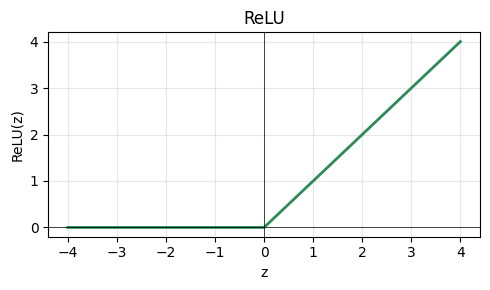

In [4]:
z = np.linspace(-4, 4, 400)
y = np.maximum(0, z)

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='seagreen', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title('ReLU'); plt.xlabel('z'); plt.ylabel('ReLU(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### Leaky ReLU  $\text{LeakyReLU}(z) = \max(\alpha z,\, z)$, with $\alpha = 0.01$

**Pros:** fixes the dying ReLU problem — negative inputs still produce a small gradient $\alpha$.  
**Cons:** $\alpha$ is a hyperparameter to tune; not always better than ReLU in practice.

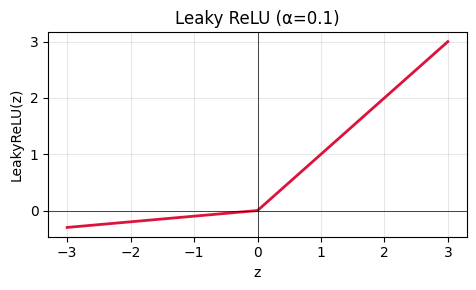

In [5]:
alpha = 0.1
z = np.linspace(-3, 3, 200)
y = np.where(z > 0, z, alpha * z)

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='crimson', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title(f'Leaky ReLU (α={alpha})'); plt.xlabel('z'); plt.ylabel('LeakyReLU(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### ELU  $\text{ELU}(z) = \begin{cases} z & z > 0 \\ \alpha(e^z - 1) & z \leq 0 \end{cases}$

**Pros:** smooth everywhere (including at $z=0$); negative saturation pushes mean activation towards 0; faster convergence than ReLU.  
**Cons:** slightly more expensive to compute (exponential); $\alpha$ is a hyperparameter.

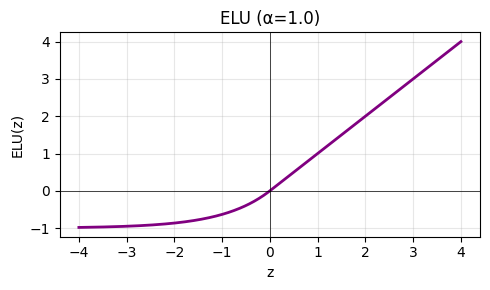

In [6]:
alpha = 1.0
z = np.linspace(-4, 4, 400)
y = np.where(z > 0, z, alpha * (np.exp(z) - 1))

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='purple', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title(f'ELU (α={alpha})'); plt.xlabel('z'); plt.ylabel('ELU(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### GELU  $\text{GELU}(z) = z\,\Phi(z)$

where $\Phi(z)$ is the standard normal CDF. In practice approximated as:

$$\text{GELU}(z) \approx 0.5z\left(1 + \tanh\!\left[\sqrt{\tfrac{2}{\pi}}\left(z + 0.044715\,z^3\right)\right]\right)$$

**Pros:** smooth, non-monotonic; stochastic regularization effect; default in BERT, GPT, and most modern Transformers.  
**Cons:** more expensive than ReLU; less intuitive than simpler functions.

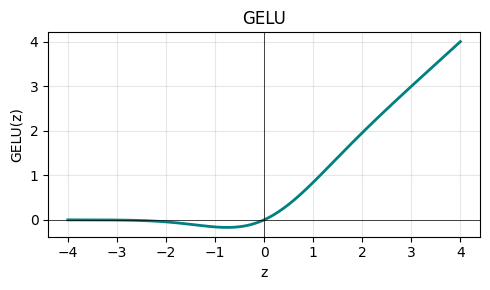

In [7]:
z = np.linspace(-4, 4, 400)
y = 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z**3)))

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='teal', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title('GELU'); plt.xlabel('z'); plt.ylabel('GELU(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### Swish  $\text{Swish}(z) = z \cdot \sigma(z) = \dfrac{z}{1+e^{-z}}$

**Pros:** smooth, non-monotonic, self-gated; empirically outperforms ReLU on deep networks; no hyperparameters.  
**Cons:** slightly more expensive than ReLU; small dip below zero can be unexpected.

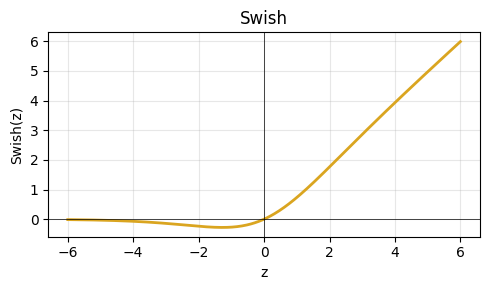

In [8]:
z = np.linspace(-6, 6, 400)
y = z / (1 + np.exp(-z))

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='goldenrod', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title('Swish'); plt.xlabel('z'); plt.ylabel('Swish(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### Softmax  $\text{Softmax}(z_i) = \dfrac{e^{z_i}}{\displaystyle\sum_{j=1}^{K} e^{z_j}}$

**Pros:** outputs form a valid probability distribution (all positive, sum to 1); ideal for multi-class classification output layer; pairs naturally with cross-entropy loss.  
**Cons:** used **only in the output layer**, not hidden layers; expensive for very large $K$ (e.g. large vocabularies); sensitive to large logit differences (can saturate).

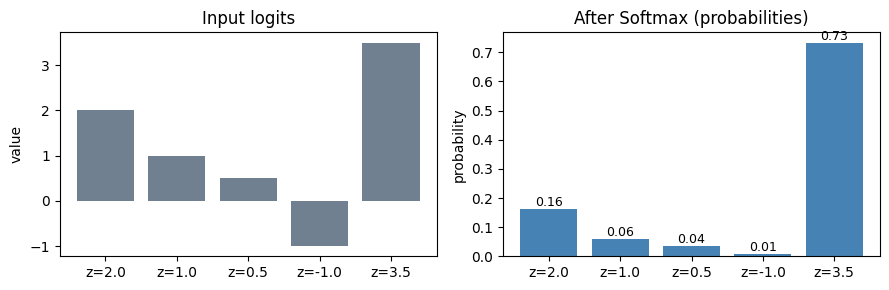

Sum of probabilities: 1.0000


In [9]:
logits = np.array([2.0, 1.0, 0.5, -1.0, 3.5])
probs  = np.exp(logits) / np.exp(logits).sum()
labels = [f'z={v}' for v in logits]

fig, axes = plt.subplots(1, 2, figsize=(9, 3))

axes[0].bar(labels, logits, color='slategray')
axes[0].set_title('Input logits'); axes[0].set_ylabel('value')

axes[1].bar(labels, probs, color='steelblue')
axes[1].set_title('After Softmax (probabilities)')
axes[1].set_ylabel('probability')
for i, p in enumerate(probs):
    axes[1].text(i, p + 0.01, f'{p:.2f}', ha='center', fontsize=9)

plt.tight_layout(); plt.show()
print(f'Sum of probabilities: {probs.sum():.4f}')